In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv('insurance.csv')

print("Data berhasil dimuat!")
print("Jumlah baris dan kolom:", df.shape)

df.head()

Data berhasil dimuat!
Jumlah baris dan kolom: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# Informasi dataset
df.info()

# Statistik deskriptif
display(df.describe())

# Statistik kolom kategorikal
display(df.describe(include='object'))

# Memeriksa missing values
print("Missing values setiap kolom:")
print(df.isnull().sum())

# Memeriksa jumlah data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


Missing values setiap kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Jumlah data duplikat: 1


In [4]:
# Menghapus data duplikat
df = df.drop_duplicates().copy()

print("Jumlah data setelah menghapus duplikat:", df.shape)

# Memeriksa kembali missing values
print("\nMissing values setelah menghapus duplikat:")
print(df.isnull().sum())

# Mengisi missing values jika ada
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

print("\nJumlah missing values setelah cleaning:")
print(df.isnull().sum())

display(df.head())

Jumlah data setelah menghapus duplikat: (1337, 7)

Missing values setelah menghapus duplikat:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah missing values setelah cleaning:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
kolom_numerik = ['age', 'bmi', 'children', 'charges']

for col in kolom_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ).sum()

    print(f"{col}: {jumlah_outlier} outlier")

age: 0 outlier
bmi: 9 outlier
children: 0 outlier
charges: 139 outlier


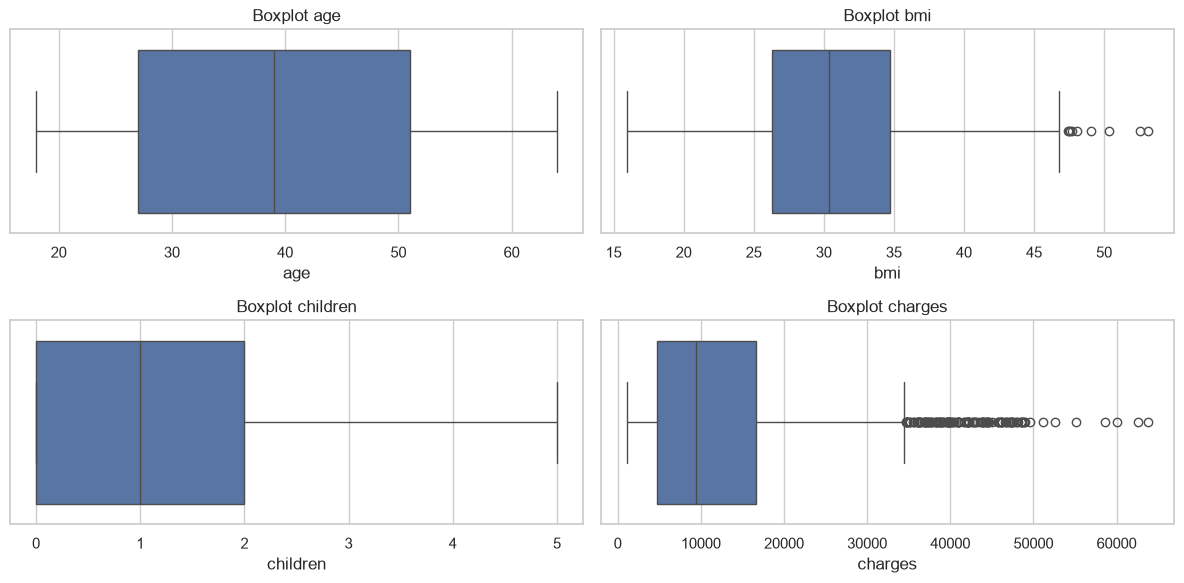

In [6]:
plt.figure(figsize=(12, 6))

for i, col in enumerate(kolom_numerik, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(x=df[col], color='C0')
    plt.title(f'Boxplot {col}')

plt.tight_layout()
plt.show()